# Assignment 5 — Image Smoothing (Spatial Filtering)

> **Question:** Write a program to smooth the input image using:
> 1. Averaging filter (un-weighted)
> 2. Weighted filter given by $h(x,y) = \max(|x|, |y|)$
> 3. Gaussian filter
>
> **Note:** Input the filter size and other parameters such as sigma in case of the Gaussian filter, method of padding (replication, zero padding, etc.) from the user.

**Method:** The image is padded by $a = \lfloor n/2 \rfloor$ pixels using the chosen method, then each output pixel is the weighted sum of its $n \times n$ neighbourhood:
$$ g(x,y) = \sum_{s=-a}^{a} \sum_{t=-a}^{a} w(s,t)\, f(x+s, y+t) $$
All kernels are normalised so their weights add up to 1, which keeps the overall brightness the same.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
from skimage import data

plt.rcParams['figure.dpi'] = 100


def ask(prompt, default, cast=float):
    """Read a value from the user.
    If the user just presses Enter, types something invalid, or the notebook is
    run non-interactively (no keyboard input possible), the default is used."""
    try:
        text = input(f"{prompt} [default = {default}]: ").strip()
        return cast(text) if text else default
    except Exception:
        print(f"{prompt}: no valid input, using default = {default}")
        return default


def show(images, titles, cols=None, size=4):
    """Display a list of images side by side (grayscale shown on a fixed 0-255 scale)."""
    n = len(images)
    cols = cols or n
    rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(size * cols, size * rows))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes:
        ax.axis('off')
    for ax, im, t in zip(axes, images, titles):
        if im.ndim == 2:
            ax.imshow(im, cmap='gray', vmin=0, vmax=1 if im.max() <= 1 else 255)
        else:
            ax.imshow(im)
        ax.set_title(t)
    plt.tight_layout()
    plt.show()

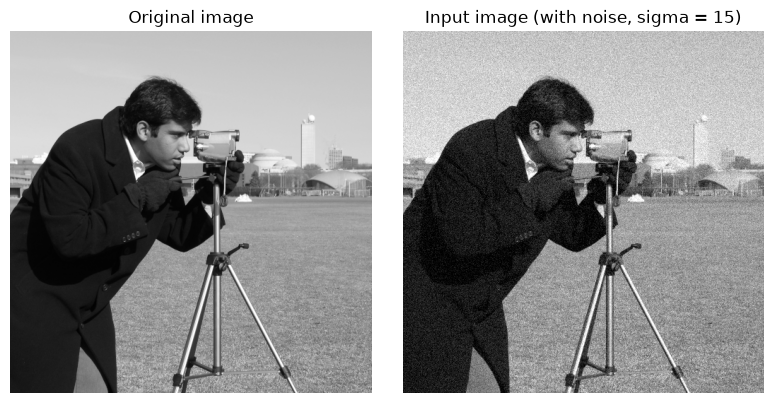

In [2]:
IMAGE_PATH = None   # e.g. "my_image.jpg"
clean = cv2.imread(IMAGE_PATH, cv2.IMREAD_GRAYSCALE) if IMAGE_PATH else data.camera()

# a little Gaussian noise is added so that the smoothing effect is clearly visible
rng = np.random.default_rng(0)
img = np.clip(clean + rng.normal(0, 15, clean.shape), 0, 255).astype(np.uint8)
show([clean, img], ['Original image', 'Input image (with noise, sigma = 15)'])

## Padding and filtering functions (implemented from scratch)

In [3]:
def pad_image(image, a, method):
    """Pad by `a` pixels on every side.
    zero      : 0 0 | 1 2 3 | 0 0
    replicate : 1 1 | 1 2 3 | 3 3
    symmetric : 2 1 | 1 2 3 | 3 2   (mirror)
    circular  : 2 3 | 1 2 3 | 1 2   (wrap around)"""
    h, w = image.shape
    if method == 'zero':
        out = np.zeros((h + 2 * a, w + 2 * a), dtype=image.dtype)
        out[a:a + h, a:a + w] = image
        return out
    if method == 'replicate':
        rows = np.clip(np.arange(-a, h + a), 0, h - 1)
        cols = np.clip(np.arange(-a, w + a), 0, w - 1)
    elif method == 'symmetric':
        rows = np.arange(-a, h + a); rows = np.where(rows < 0, -rows - 1, np.where(rows >= h, 2 * h - rows - 1, rows))
        cols = np.arange(-a, w + a); cols = np.where(cols < 0, -cols - 1, np.where(cols >= w, 2 * w - cols - 1, cols))
    elif method == 'circular':
        rows = np.arange(-a, h + a) % h
        cols = np.arange(-a, w + a) % w
    else:
        raise ValueError("padding must be zero / replicate / symmetric / circular")
    return image[np.ix_(rows, cols)]


def filter2d(image, kernel, padding='replicate'):
    """Correlate `image` with `kernel` (all kernels here are symmetric, so this equals convolution)."""
    n = kernel.shape[0]
    a = n // 2
    f = pad_image(image.astype(np.float64), a, padding)
    h, w = image.shape
    out = np.zeros((h, w))
    for s in range(n):                 # loop over kernel positions, add shifted images
        for t in range(n):
            out += kernel[s, t] * f[s:s + h, t:t + w]
    return np.clip(np.round(out), 0, 255).astype(np.uint8)

## Kernels

In [4]:
def average_kernel(n):
    return np.ones((n, n)) / (n * n)


def max_weighted_kernel(n):
    """h(x, y) = max(|x|, |y|) with (0, 0) at the centre, normalised to sum to 1."""
    a = n // 2
    y, x = np.mgrid[-a:a + 1, -a:a + 1]
    h = np.maximum(np.abs(x), np.abs(y)).astype(np.float64)
    return h / h.sum()


def gaussian_kernel(n, sigma):
    a = n // 2
    y, x = np.mgrid[-a:a + 1, -a:a + 1]
    h = np.exp(-(x ** 2 + y ** 2) / (2 * sigma ** 2))
    return h / h.sum()

## User input

In [5]:
n = ask("Enter filter size n (odd, >= 3)", 5, int)
if n < 3 or n % 2 == 0:
    n = max(3, n + (n % 2 == 0))
    print("Filter size must be odd and >= 3 -> using", n)
sigma = ask("Enter sigma for the Gaussian filter", 1.5)
padding = ask("Enter padding method (zero / replicate / symmetric / circular)", 'replicate', str).lower()
if padding not in ('zero', 'replicate', 'symmetric', 'circular'):
    print("Unknown padding -> using replicate"); padding = 'replicate'

K_avg, K_max, K_gau = average_kernel(n), max_weighted_kernel(n), gaussian_kernel(n, sigma)
np.set_printoptions(precision=4, suppress=True)
print(f"\nAveraging kernel ({n}x{n}):\n", K_avg)
print(f"\nWeighted kernel max(|x|,|y|) ({n}x{n}), before normalising:\n", K_max / K_max[K_max > 0].min())
print(f"\nWeighted kernel max(|x|,|y|), normalised:\n", K_max)
print(f"\nGaussian kernel ({n}x{n}, sigma={sigma}):\n", K_gau)

Enter filter size n (odd, >= 3): no valid input, using default = 5
Enter sigma for the Gaussian filter: no valid input, using default = 1.5
Enter padding method (zero / replicate / symmetric / circular): no valid input, using default = replicate

Averaging kernel (5x5):
 [[0.04 0.04 0.04 0.04 0.04]
 [0.04 0.04 0.04 0.04 0.04]
 [0.04 0.04 0.04 0.04 0.04]
 [0.04 0.04 0.04 0.04 0.04]
 [0.04 0.04 0.04 0.04 0.04]]

Weighted kernel max(|x|,|y|) (5x5), before normalising:
 [[2. 2. 2. 2. 2.]
 [2. 1. 1. 1. 2.]
 [2. 1. 0. 1. 2.]
 [2. 1. 1. 1. 2.]
 [2. 2. 2. 2. 2.]]

Weighted kernel max(|x|,|y|), normalised:
 [[0.05  0.05  0.05  0.05  0.05 ]
 [0.05  0.025 0.025 0.025 0.05 ]
 [0.05  0.025 0.    0.025 0.05 ]
 [0.05  0.025 0.025 0.025 0.05 ]
 [0.05  0.05  0.05  0.05  0.05 ]]

Gaussian kernel (5x5, sigma=1.5):
 [[0.0144 0.0281 0.0351 0.0281 0.0144]
 [0.0281 0.0547 0.0683 0.0547 0.0281]
 [0.0351 0.0683 0.0853 0.0683 0.0351]
 [0.0281 0.0547 0.0683 0.0547 0.0281]
 [0.0144 0.0281 0.0351 0.0281 0.0144]]


## Results

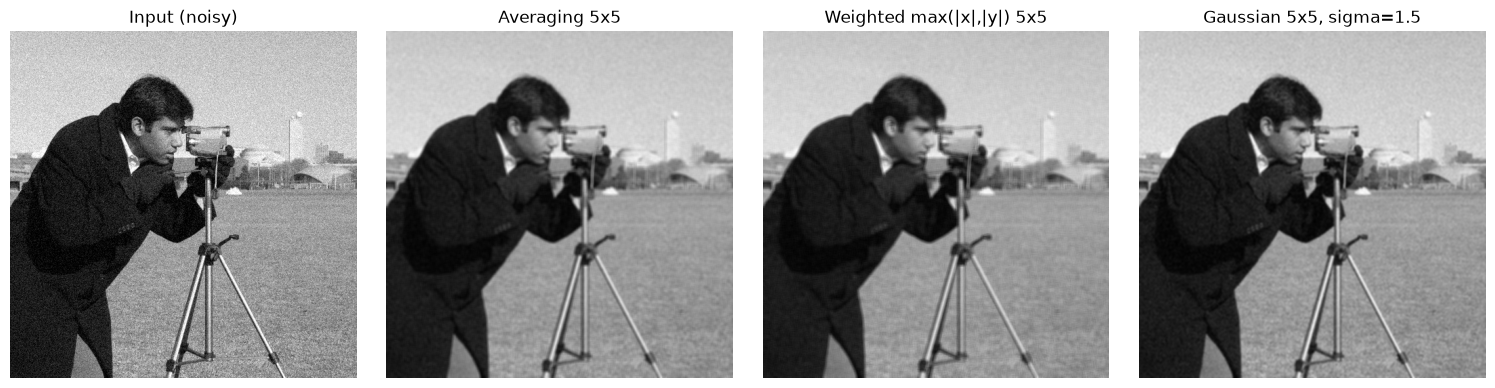

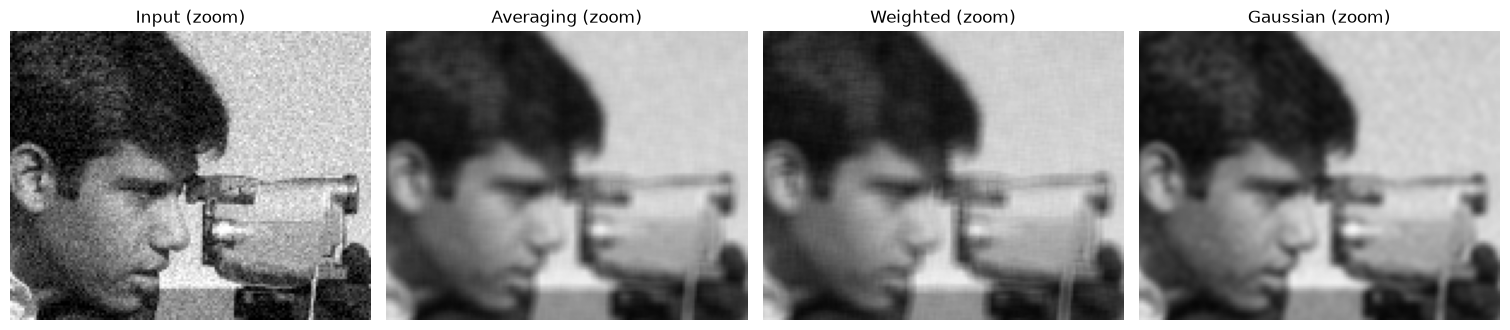

PSNR w.r.t. clean image -> noisy: 24.80 dB | averaging: 26.43 dB | weighted: 25.62 dB | gaussian: 27.57 dB


In [6]:
out_avg = filter2d(img, K_avg, padding)
out_max = filter2d(img, K_max, padding)
out_gau = filter2d(img, K_gau, padding)

show([img, out_avg, out_max, out_gau],
     ['Input (noisy)', f'Averaging {n}x{n}', f'Weighted max(|x|,|y|) {n}x{n}', f'Gaussian {n}x{n}, sigma={sigma}'],
     cols=4, size=3.8)

# zoomed crop to see the difference more clearly
crop = (slice(80, 200), slice(180, 330))
show([img[crop], out_avg[crop], out_max[crop], out_gau[crop]],
     ['Input (zoom)', 'Averaging (zoom)', 'Weighted (zoom)', 'Gaussian (zoom)'], cols=4, size=3.8)

def psnr(a, b):
    mse = np.mean((a.astype(float) - b.astype(float)) ** 2)
    return 10 * np.log10(255 ** 2 / mse)
print(f"PSNR w.r.t. clean image -> noisy: {psnr(clean, img):.2f} dB | averaging: {psnr(clean, out_avg):.2f} dB | "
      f"weighted: {psnr(clean, out_max):.2f} dB | gaussian: {psnr(clean, out_gau):.2f} dB")

## Effect of the padding method
A large 31×31 averaging filter makes the border effects easy to see. Zero padding darkens the edges because black pixels are averaged in, while replicate, symmetric and circular padding avoid this.

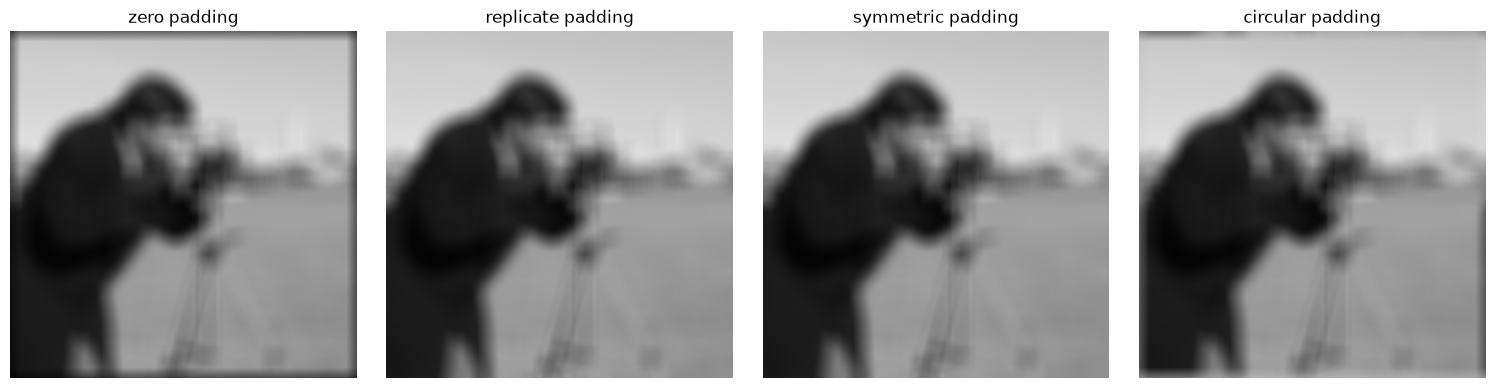

In [7]:
methods = ['zero', 'replicate', 'symmetric', 'circular']
big = average_kernel(31)
show([filter2d(clean, big, m) for m in methods], [f'{m} padding' for m in methods], cols=4, size=3.8)

## Verification against OpenCV

In [8]:
ref_avg = cv2.blur(img, (n, n), borderType=cv2.BORDER_REPLICATE)
ref_gau = cv2.filter2D(img.astype(np.float64), -1, K_gau, borderType=cv2.BORDER_REPLICATE)
ref_gau = np.clip(np.round(ref_gau), 0, 255).astype(np.uint8)
mine_avg = filter2d(img, K_avg, 'replicate'); mine_gau = filter2d(img, K_gau, 'replicate')
print("Max |difference| averaging (mine vs cv2.blur):", np.abs(mine_avg.astype(int) - ref_avg).max())
print("Max |difference| gaussian  (mine vs cv2.filter2D):", np.abs(mine_gau.astype(int) - ref_gau).max())

Max |difference| averaging (mine vs cv2.blur): 0
Max |difference| gaussian  (mine vs cv2.filter2D): 0


**Observations:**
- The **averaging filter** removes noise but blurs edges the most, because every neighbour has the same weight.
- The **weighted filter $\max(|x|,|y|)$** gives the centre pixel weight 0 and the outer rings more weight. It smooths even more strongly than averaging for the same size.
- The **Gaussian filter** gives the most weight to the centre and the weights fall off smoothly, so it removes noise while keeping edges sharper. Larger sigma means more smoothing.
- A bigger filter size gives stronger smoothing (and more blur) for every filter.
- The differences of at most 1 against OpenCV come only from rounding.